In [10]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from PIL import Image
import warnings
warnings.filterwarnings('ignore')

print("All imports OK")


All imports OK


In [11]:
CSV_PATH = '/kaggle/input/datasets/dp2302/final-merged-dataset-csv/final_merged_dataset.csv'
df = pd.read_csv(CSV_PATH)
print(f"Loaded: {len(df):,} rows")
df.head()


Loaded: 311,623 rows


,image_path,source,no_finding,Atelectasis,Cardiomegaly,Effusion,Consolidation,Edema,Pneumonia,Pneumothorax,Infiltration,Lung_Lesion,Pleural_Thickening
0,/kaggle/input/datasets/nih-chest-xrays/data/im...,NIH,0,0,0,0,0,0,0,0,1,1,0
1,/kaggle/input/datasets/nih-chest-xrays/data/im...,NIH,0,0,0,0,0,0,0,0,0,0,1
2,/kaggle/input/datasets/nih-chest-xrays/data/im...,NIH,1,0,0,0,0,0,0,0,0,0,0
3,/kaggle/input/datasets/ashery/chexpert/train/p...,CheXpert,0,0,0,1,1,0,1,0,1,0,0
4,/kaggle/input/datasets/nih-chest-xrays/data/im...,NIH,0,0,0,0,0,0,0,0,1,0,0


In [12]:
DISEASE_COLS = [
    'Atelectasis', 'Cardiomegaly', 'Effusion', 'Consolidation',
    'Edema', 'Pneumonia', 'Pneumothorax',
    'Infiltration', 'Lung_Lesion', 'Pleural_Thickening'
]

ALL_LABEL_COLS = ['no_finding'] + DISEASE_COLS

print(f"Disease classes : {len(DISEASE_COLS)}")
print(f"Total classes   : {len(ALL_LABEL_COLS)}")


Disease classes : 10
Total classes   : 11


In [13]:
print("=" * 60)
print("            DATASET OVERVIEW")
print("=" * 60)
print(f"  Total images       : {len(df):,}")
print(f"  Total columns      : {len(df.columns)}")
print(f"  NIH images         : {(df['source'] == 'NIH').sum():,}")
print(f"  CheXpert images    : {(df['source'] == 'CheXpert').sum():,}")
print(f"  Healthy (No Finding): {df['no_finding'].sum():,}")
print(f"  Diseased images    : {(df['no_finding'] == 0).sum():,}")
print("=" * 60)

# Multi-label stats
df['label_count'] = df[ALL_LABEL_COLS].sum(axis=1)
print(f"\n  Labels per image:")
for cnt, freq in df['label_count'].value_counts().sort_index().items():
    print(f"    {int(cnt)} label(s) : {freq:>8,} images  ({freq/len(df)*100:.1f}%)")
print("=" * 60)


            DATASET OVERVIEW
  Total images       : 311,623
  Total columns      : 13
  NIH images         : 110,375
  CheXpert images    : 201,248
  Healthy (No Finding): 82,780
  Diseased images    : 228,843

  Labels per image:
    1 label(s) :  175,528 images  (56.3%)
    2 label(s) :   81,697 images  (26.2%)
    3 label(s) :   41,837 images  (13.4%)
    4 label(s) :   10,978 images  (3.5%)
    5 label(s) :    1,432 images  (0.5%)
    6 label(s) :      136 images  (0.0%)
    7 label(s) :       14 images  (0.0%)
    8 label(s) :        1 images  (0.0%)


In [14]:
print("=" * 62)
print(f"  {'Disease':<22} {'NIH':>9} {'CheXpert':>10} {'Total':>9} {'%':>6}")
print("=" * 62)

nih_df_  = df[df['source'] == 'NIH']
chex_df_ = df[df['source'] == 'CheXpert']

for col in ALL_LABEL_COLS:
    nih_c  = int(nih_df_[col].sum())
    chex_c = int(chex_df_[col].sum())
    total  = nih_c + chex_c
    pct    = total / len(df) * 100
    tag    = " (healthy)" if col == 'no_finding' else ""
    print(f"  {col:<22} {nih_c:>9,} {chex_c:>10,} {total:>9,} {pct:>5.1f}%{tag}")

print("=" * 62)
print(f"  {'TOTAL IMAGES':<22} {len(nih_df_):>9,} {len(chex_df_):>10,} {len(df):>9,}")
print("=" * 62)


  Disease                      NIH   CheXpert     Total      %
  no_finding                60,361     22,419    82,780  26.6% (healthy)
  Atelectasis               11,559     33,456    45,015  14.4%
  Cardiomegaly               2,776     27,068    29,844   9.6%
  Effusion                  13,317     86,254    99,571  32.0%
  Consolidation              4,667     14,816    19,483   6.3%
  Edema                      2,303     52,291    54,594  17.5%
  Pneumonia                  1,431      6,047     7,478   2.4%
  Pneumothorax               5,302     19,456    24,758   7.9%
  Infiltration              19,894    105,707   125,601  40.3%
  Lung_Lesion               11,207      9,187    20,394   6.5%
  Pleural_Thickening         3,385      3,524     6,909   2.2%
  TOTAL IMAGES             110,375    201,248   311,623


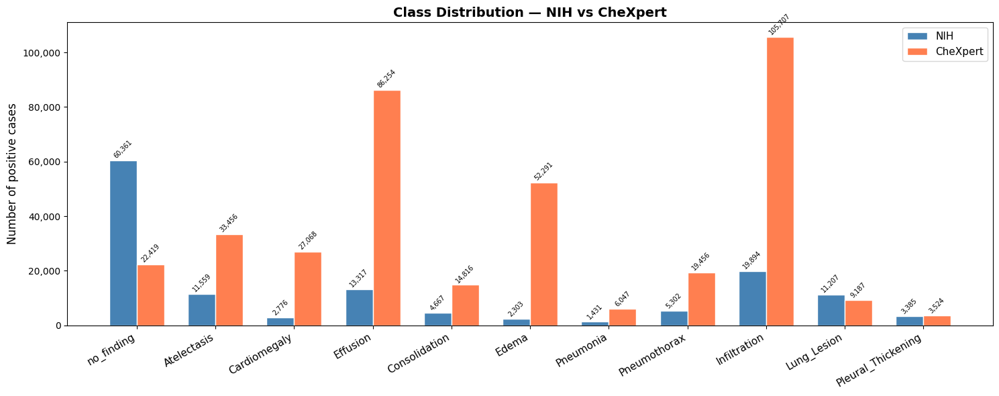

In [15]:
import matplotlib.pyplot as plt
import numpy as np

nih_counts  = df[df['source'] == 'NIH'][ALL_LABEL_COLS].sum()
chex_counts = df[df['source'] == 'CheXpert'][ALL_LABEL_COLS].sum()

x = np.arange(len(ALL_LABEL_COLS))
w = 0.35

fig, ax = plt.subplots(figsize=(15, 6))
b1 = ax.bar(x - w/2, nih_counts,  w, label='NIH',      color='steelblue', edgecolor='white')
b2 = ax.bar(x + w/2, chex_counts, w, label='CheXpert',  color='coral',    edgecolor='white')

for bar in [*b1, *b2]:
    h = bar.get_height()
    if h > 0:
        ax.text(bar.get_x() + bar.get_width()/2, h + 300,
                f'{int(h):,}', ha='center', va='bottom', fontsize=7, rotation=45)

ax.set_xticks(x)
ax.set_xticklabels(ALL_LABEL_COLS, rotation=30, ha='right', fontsize=11)
ax.set_ylabel('Number of positive cases', fontsize=12)
ax.set_title('Class Distribution — NIH vs CheXpert', fontsize=14, fontweight='bold')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{int(v):,}'))
ax.legend(fontsize=11)
plt.tight_layout()
plt.show()


In [18]:
print("=== DIAGNOSIS ===\n")

# 1. Check actual column names in df
print("Columns in df:")
print(df.columns.tolist())

# 2. Check dtypes
print("\nDtypes of label columns:")
print(df[ALL_LABEL_COLS].dtypes)

# 3. Check sum of each label
print("\nSum of each label column:")
print(df[ALL_LABEL_COLS].sum())

# 4. Check unique values in label columns
print("\nUnique values in Atelectasis column:")
print(df['Atelectasis'].unique())

# 5. Check a few raw rows
print("\nFirst 5 rows of label columns:")
print(df[ALL_LABEL_COLS].head())

# 6. Check if df_valid == df
print(f"\ndf rows      : {len(df):,}")



=== DIAGNOSIS ===

Columns in df:
['image_path', 'source', 'no_finding', 'Atelectasis', 'Cardiomegaly', 'Effusion', 'Consolidation', 'Edema', 'Pneumonia', 'Pneumothorax', 'Infiltration', 'Lung_Lesion', 'Pleural_Thickening', 'label_count']

Dtypes of label columns:
no_finding            int64
Atelectasis           int64
Cardiomegaly          int64
Effusion              int64
Consolidation         int64
Edema                 int64
Pneumonia             int64
Pneumothorax          int64
Infiltration          int64
Lung_Lesion           int64
Pleural_Thickening    int64
dtype: object

Sum of each label column:
no_finding             82780
Atelectasis            45015
Cardiomegaly           29844
Effusion               99571
Consolidation          19483
Edema                  54594
Pneumonia               7478
Pneumothorax           24758
Infiltration          125601
Lung_Lesion            20394
Pleural_Thickening      6909
dtype: int64

Unique values in Atelectasis column:
[0 1]

First 5 r

In [19]:
import os

print("=== All available input folders ===")
def list_tree(path, depth=0, max_depth=3):
    if depth > max_depth:
        return
    try:
        items = sorted(os.listdir(path))
        for item in items[:5]:  # show first 5 items only
            full = os.path.join(path, item)
            print("  " * depth + f"{'/' if os.path.isdir(full) else ''}{item}")
            if os.path.isdir(full):
                list_tree(full, depth+1, max_depth)
        if len(items) > 5:
            print("  " * depth + f"... ({len(items)-5} more)")
    except:
        pass

list_tree('/kaggle/input')


=== All available input folders ===
/datasets
  /ashery
    /chexpert
      /train
      train.csv
      /valid
      valid.csv
  /dp2302
    /final-merged-dataset-csv
      final_merged_dataset.csv
  /nih-chest-xrays
    /data
      ARXIV_V5_CHESTXRAY.pdf
      BBox_List_2017.csv
      Data_Entry_2017.csv
      FAQ_CHESTXRAY.pdf
      LOG_CHESTXRAY.pdf
      ... (15 more)


In [20]:
# After adding datasets, check exact mount paths
print("Checking NIH path...")
nih_test = '/kaggle/input/datasets/nih-chest-xrays/data/images_001/images'
print(f"  Exists: {os.path.exists(nih_test)}")

print("\nChecking CheXpert path...")
chex_test = '/kaggle/input/datasets/ashery/chexpert/train'
print(f"  Exists: {os.path.exists(chex_test)}")


Checking NIH path...
  Exists: True

Checking CheXpert path...
  Exists: True


In [23]:
import os

# Fast check — sirf 1000 random paths check karo pehle
sample_check = df['image_path'].sample(1000, random_state=42)
sample_exists = sample_check.apply(os.path.exists)

print(f"Quick check (1000 samples):")
print(f"  Found   : {sample_exists.sum()}")
print(f"  Missing : {(~sample_exists).sum()}")

if sample_exists.sum() > 950:
    print("\n  Paths look correct! Skipping full scan...")
    print("  Using full df directly as df_valid (all paths assumed valid)")

    # Skip the slow os.path.exists check — just use full df
    df_valid = df.copy().reset_index(drop=True)
    df_valid['label_count'] = df_valid[ALL_LABEL_COLS].sum(axis=1)

    print(f"\ndf_valid shape : {df_valid.shape}")
    print(f"\nLabel sums:")
    print(df_valid[ALL_LABEL_COLS].sum().sort_values(ascending=False))
else:
    print("\n  Some paths missing — running full check...")
    exists_mask = df['image_path'].apply(os.path.exists)
    df_valid = df[exists_mask].copy().reset_index(drop=True)
    df_valid['label_count'] = df_valid[ALL_LABEL_COLS].sum(axis=1)
    print(f"Paths found  : {exists_mask.sum():,}")
    print(f"df_valid shape: {df_valid.shape}")
     

Quick check (1000 samples):
  Found   : 1000
  Missing : 0

  Paths look correct! Skipping full scan...
  Using full df directly as df_valid (all paths assumed valid)

df_valid shape : (311623, 14)

Label sums:
Infiltration          125601
Effusion               99571
no_finding             82780
Edema                  54594
Atelectasis            45015
Cardiomegaly           29844
Pneumothorax           24758
Lung_Lesion            20394
Consolidation          19483
Pneumonia               7478
Pleural_Thickening      6909
dtype: int64


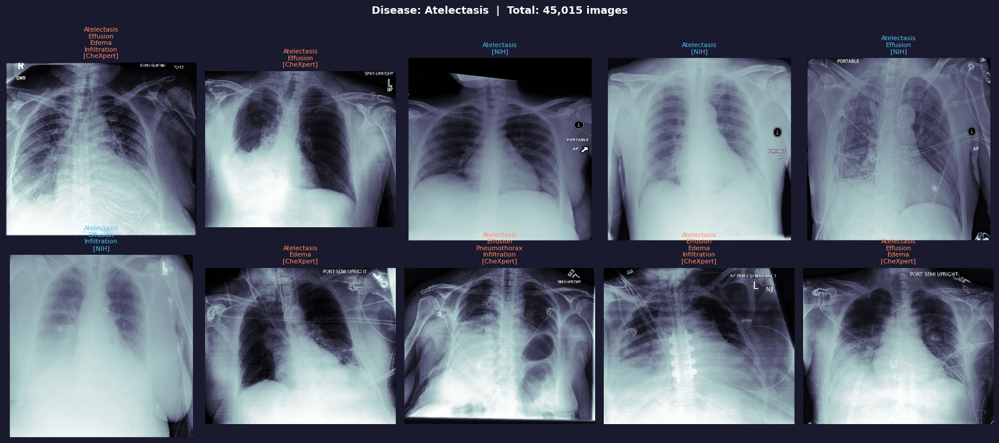

  Atelectasis: 45,015 total | NIH: 11,559 | CheXpert: 33,456



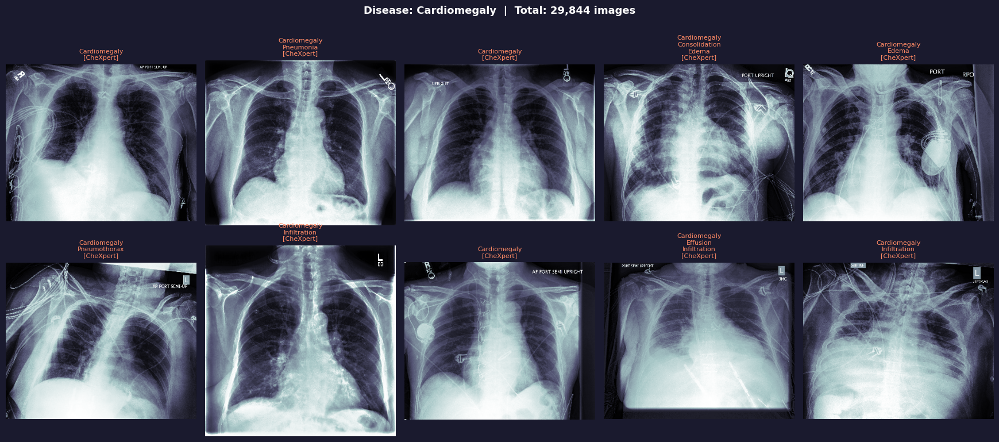

  Cardiomegaly: 29,844 total | NIH: 2,776 | CheXpert: 27,068



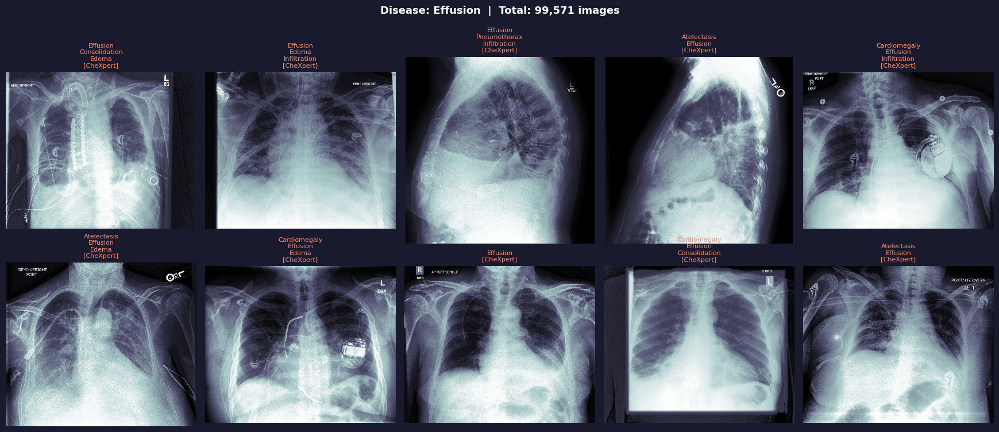

  Effusion: 99,571 total | NIH: 13,317 | CheXpert: 86,254



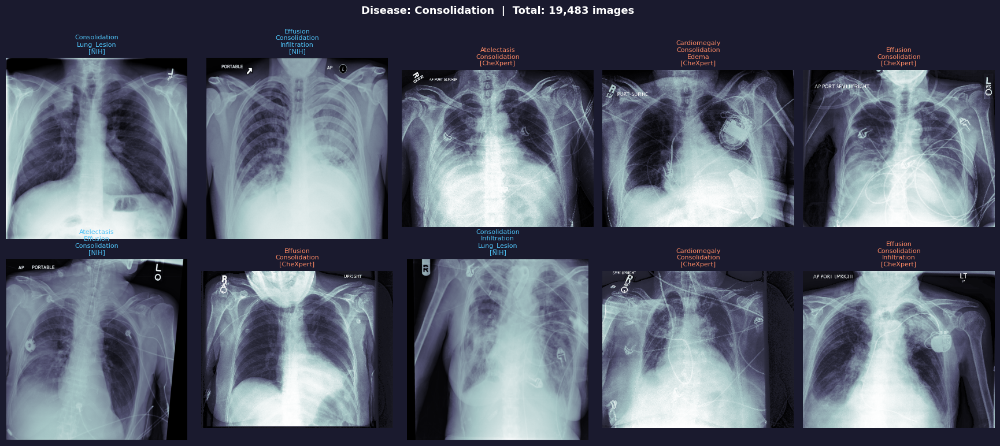

  Consolidation: 19,483 total | NIH: 4,667 | CheXpert: 14,816



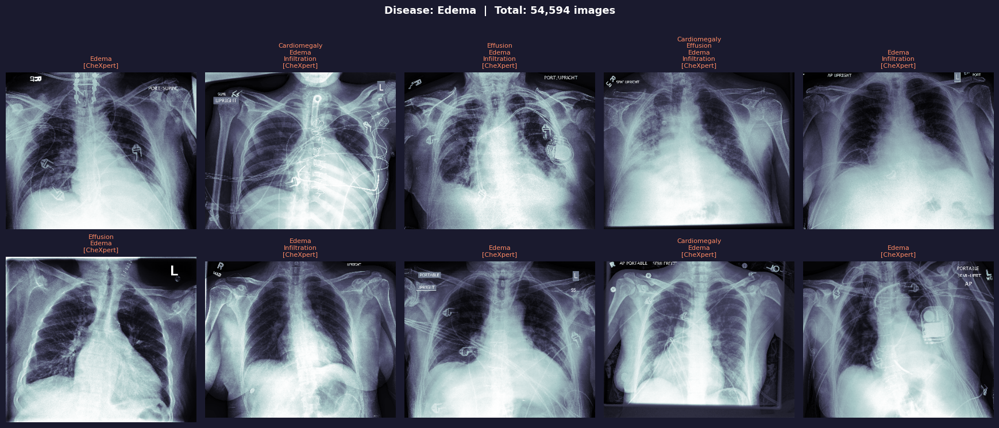

  Edema: 54,594 total | NIH: 2,303 | CheXpert: 52,291



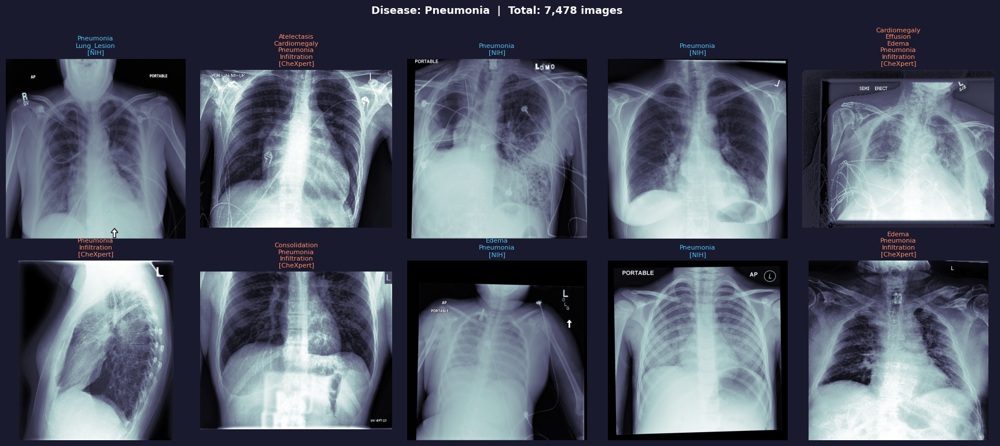

  Pneumonia: 7,478 total | NIH: 1,431 | CheXpert: 6,047



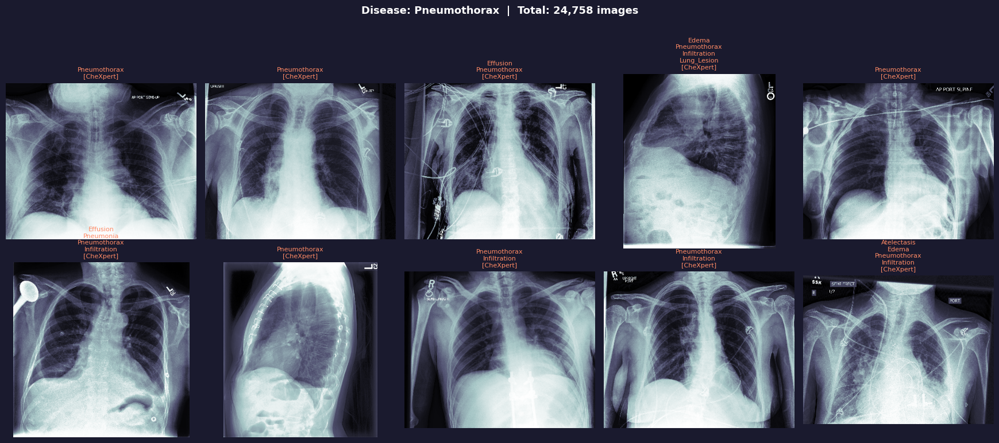

  Pneumothorax: 24,758 total | NIH: 5,302 | CheXpert: 19,456



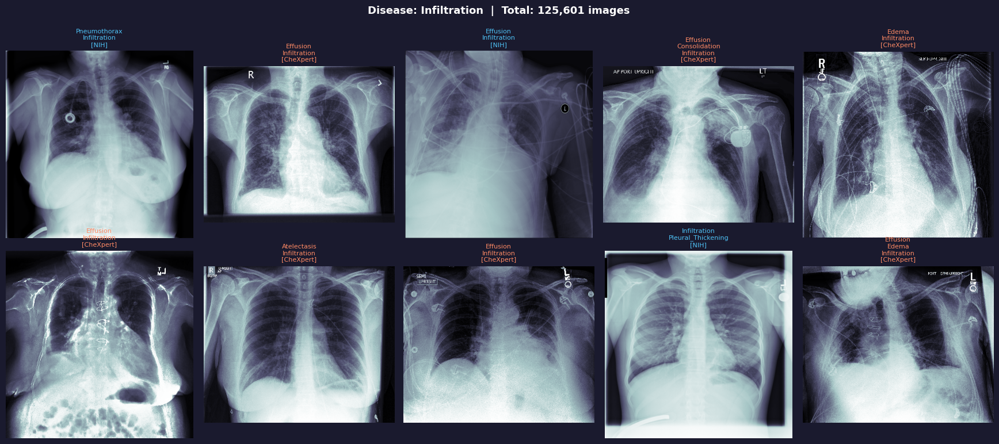

  Infiltration: 125,601 total | NIH: 19,894 | CheXpert: 105,707



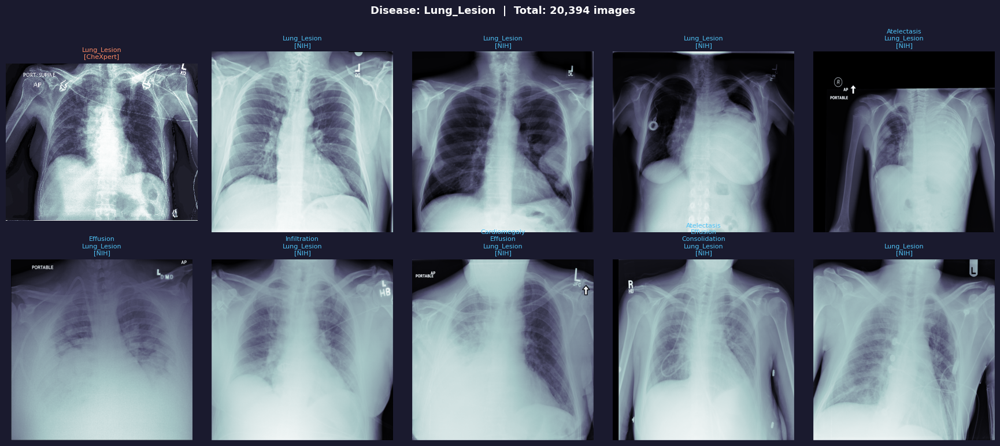

  Lung_Lesion: 20,394 total | NIH: 11,207 | CheXpert: 9,187



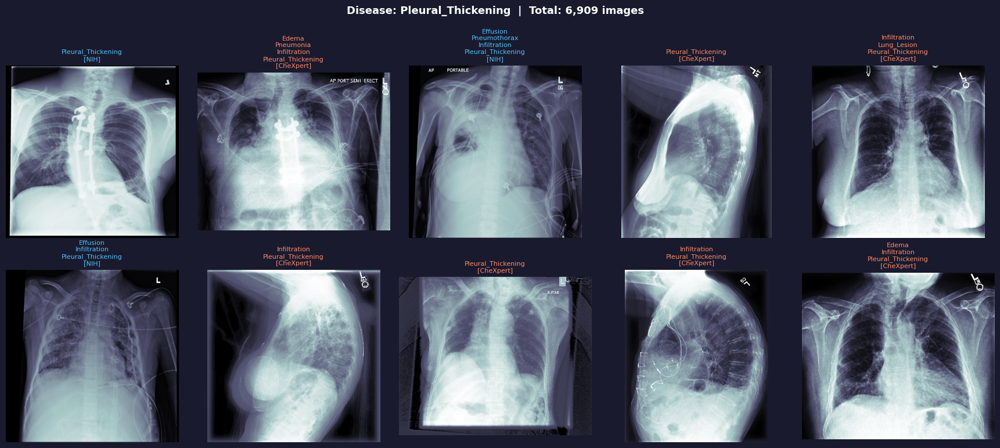

  Pleural_Thickening: 6,909 total | NIH: 3,385 | CheXpert: 3,524



In [24]:
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

def show_disease_samples(dataframe, disease, n=10, cols=5):
    subset = dataframe[dataframe[disease] == 1]

    if len(subset) == 0:
        print(f"No images found for {disease}")
        return

    sample = subset.sample(min(n, len(subset)), random_state=42).reset_index(drop=True)
    rows   = (n + cols - 1) // cols

    fig, axes = plt.subplots(rows, cols, figsize=(cols * 3.5, rows * 3.8))
    axes = np.array(axes).flatten()
    fig.patch.set_facecolor('#1a1a2e')

    for i, (_, row) in enumerate(sample.iterrows()):
        try:
            img    = Image.open(row['image_path']).convert('L')
            active = [c for c in ALL_LABEL_COLS if row[c] == 1]
            src    = row['source']
            color  = '#4fc3f7' if src == 'NIH' else '#ff8a65'

            axes[i].imshow(img, cmap='bone')
            axes[i].set_title('\n'.join(active) + f'\n[{src}]',
                              fontsize=8, color=color)
            axes[i].axis('off')

            for spine in axes[i].spines.values():
                spine.set_edgecolor(color)
                spine.set_linewidth(2)
                spine.set_visible(True)

        except Exception as e:
            axes[i].set_title(f"Error", fontsize=8, color='red')
            axes[i].axis('off')

    for j in range(i + 1, len(axes)):
        axes[j].axis('off')

    fig.suptitle(f'Disease: {disease}  |  Total: {len(subset):,} images',
                 fontsize=13, fontweight='bold', color='white', y=1.01)
    plt.tight_layout()
    plt.show()
    print(f"  {disease}: {len(subset):,} total | NIH: {(subset['source']=='NIH').sum():,} | CheXpert: {(subset['source']=='CheXpert').sum():,}\n")

# Show 10 random X-rays for every disease class
for disease in DISEASE_COLS:
    show_disease_samples(df_valid, disease, n=10, cols=5)


In [17]:
#  import os
# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt
# from PIL import Image
# from tqdm.notebook import tqdm
# import warnings
# warnings.filterwarnings('ignore')

# import torch
# import torch.nn as nn
# import torch.optim as optim
# from torch.utils.data import Dataset, DataLoader
# import torchvision.transforms as T
# import torchvision.models as models

# from sklearn.model_selection import train_test_split
# from sklearn.metrics import roc_auc_score, classification_report
# import torch.cuda.amp as amp  # mixed precision

# # Device
# device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
# print(f"Device  : {device}")
# if torch.cuda.is_available():
#     print(f"GPU     : {torch.cuda.get_device_name(0)}")
#     print(f"VRAM    : {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")


Device  : cuda
GPU     : Tesla T4
VRAM    : 15.6 GB


In [25]:
# class CFG:
#     # ── Data ──────────────────────────────────────────────
#     CSV_PATH    = '/kaggle/input/datasets/dp2302/final-merged-dataset-csv/final_merged_dataset.csv'
#     IMG_SIZE    = 224
#     NUM_CLASSES = 10          # 10 disease classes (no_finding excluded from training target)

#     # ── Training ──────────────────────────────────────────
#     EPOCHS      = 5
#     BATCH_SIZE  = 64         # reduce to 16 if OOM error
#     LR          = 1e-4
#     WEIGHT_DECAY= 1e-5
#     NUM_WORKERS = 4
#     SAMPLE_FRAC  = 0.20
#     # ── Splits ────────────────────────────────────────────
#     VAL_SIZE    = 0.10        # 10% validation
#     TEST_SIZE   = 0.10        # 10% test
#     SEED        = 42

#     # ── Paths ─────────────────────────────────────────────
#     SAVE_DIR    = '/kaggle/working'
#     MODEL_NAME  = 'final_model.pt'
#     FREEZE_BACKBONE = True

#     # ── Disease columns ───────────────────────────────────
#     DISEASE_COLS = [
#         'Atelectasis', 'Cardiomegaly', 'Effusion', 'Consolidation',
#         'Edema', 'Pneumonia', 'Pneumothorax',
#         'Infiltration', 'Lung_Lesion', 'Pleural_Thickening'
#     ]

# print("Config ready")
# print(f"  Classes    : {CFG.NUM_CLASSES}")
# print(f"  Image size : {CFG.IMG_SIZE}x{CFG.IMG_SIZE}")
# print(f"  Epochs     : {CFG.EPOCHS}")
# print(f"  Batch size : {CFG.BATCH_SIZE}")


Config ready
  Classes    : 10
  Image size : 224x224
  Epochs     : 5
  Batch size : 64


In [26]:
# df = pd.read_csv(CFG.CSV_PATH)

# # Sample 20% stratified
# df = df.groupby('source', group_keys=False).apply(
#     lambda x: x.sample(frac=0.20, random_state=CFG.SEED)
# ).reset_index(drop=True)

# print(f"Sampled dataset: {len(df):,} rows")
# # Output: ~62,000 rows


# # Fix dtypes
# for col in CFG.DISEASE_COLS + ['no_finding']:
#     df[col] = pd.to_numeric(df[col], errors='coerce').fillna(0).astype(int)

# print(f"Total rows : {len(df):,}")

# # ── Train / Val / Test split ──────────────────────────────
# # Split stratified by source to keep NIH/CheXpert ratio balanced
# train_df, temp_df = train_test_split(
#     df, test_size=CFG.VAL_SIZE + CFG.TEST_SIZE,
#     random_state=CFG.SEED, stratify=df['source']
# )
# val_df, test_df = train_test_split(
#     temp_df, test_size=0.5,
#     random_state=CFG.SEED, stratify=temp_df['source']
# )

# train_df = train_df.reset_index(drop=True)
# val_df   = val_df.reset_index(drop=True)
# test_df  = test_df.reset_index(drop=True)

# print(f"\nTrain : {len(train_df):,} ({len(train_df)/len(df)*100:.1f}%)")
# print(f"Val   : {len(val_df):,}   ({len(val_df)/len(df)*100:.1f}%)")
# print(f"Test  : {len(test_df):,}   ({len(test_df)/len(df)*100:.1f}%)")

# # Verify label distribution is preserved
# print("\nTrain label sums:")
# print(train_df[CFG.DISEASE_COLS].sum().sort_values(ascending=False))


Sampled dataset: 62,325 rows
Total rows : 62,325

Train : 49,860 (80.0%)
Val   : 6,232   (10.0%)
Test  : 6,233   (10.0%)

Train label sums:
Infiltration          20005
Effusion              15915
Edema                  8779
Atelectasis            7179
Cardiomegaly           4751
Pneumothorax           3911
Lung_Lesion            3262
Consolidation          3169
Pneumonia              1263
Pleural_Thickening     1037
dtype: int64


In [27]:
# class ChestXrayDataset(Dataset):
#     def __init__(self, dataframe, transform=None, mode='train'):
#         self.df        = dataframe.reset_index(drop=True)
#         self.transform = transform
#         self.mode      = mode

#     def __len__(self):
#         return len(self.df)

#     def __getitem__(self, idx):
#         row = self.df.iloc[idx]

#         # Load image
#         try:
#             img = Image.open(row['image_path']).convert('RGB')
#         except Exception:
#             # Return black image if file fails to load
#             img = Image.new('RGB', (CFG.IMG_SIZE, CFG.IMG_SIZE), 0)

#         if self.transform:
#             img = self.transform(img)

#         # Labels — 10 disease classes
#         labels = torch.tensor(
#             row[CFG.DISEASE_COLS].values.astype(np.float32),
#             dtype=torch.float32
#         )

#         return img, labels

# # ── Transforms ────────────────────────────────────────────────────────────────
# # ImageNet stats work well for chest X-rays too
# MEAN = [0.485, 0.456, 0.406]
# STD  = [0.229, 0.224, 0.225]

# train_transform = T.Compose([
#     T.Resize((CFG.IMG_SIZE + 32, CFG.IMG_SIZE + 32)),
#     T.RandomCrop(CFG.IMG_SIZE),
#     T.RandomHorizontalFlip(p=0.5),
#     T.RandomRotation(degrees=10),
#     T.ColorJitter(brightness=0.2, contrast=0.2),
#     T.ToTensor(),
#     T.Normalize(MEAN, STD),
# ])

# val_transform = T.Compose([
#     T.Resize((CFG.IMG_SIZE, CFG.IMG_SIZE)),
#     T.ToTensor(),
#     T.Normalize(MEAN, STD),
# ])

# # ── DataLoaders ───────────────────────────────────────────────────────────────
# train_dataset = ChestXrayDataset(train_df, transform=train_transform, mode='train')
# val_dataset   = ChestXrayDataset(val_df,   transform=val_transform,   mode='val')
# test_dataset  = ChestXrayDataset(test_df,  transform=val_transform,   mode='test')

# train_loader = DataLoader(train_dataset, batch_size=CFG.BATCH_SIZE,
#                           shuffle=True,  num_workers=CFG.NUM_WORKERS, pin_memory=True)
# val_loader   = DataLoader(val_dataset,   batch_size=CFG.BATCH_SIZE,
#                           shuffle=False, num_workers=CFG.NUM_WORKERS, pin_memory=True)
# test_loader  = DataLoader(test_dataset,  batch_size=CFG.BATCH_SIZE,
#                           shuffle=False, num_workers=CFG.NUM_WORKERS, pin_memory=True)

# print(f"Train batches : {len(train_loader):,}")
# print(f"Val batches   : {len(val_loader):,}")
# print(f"Test batches  : {len(test_loader):,}")

# # Quick sanity check — load one batch
# imgs, labels = next(iter(train_loader))
# print(f"\nBatch image shape : {imgs.shape}")
# print(f"Batch label shape : {labels.shape}")
# print(f"Label sample      : {labels[0].tolist()}")


Train batches : 780
Val batches   : 98
Test batches  : 98

Batch image shape : torch.Size([64, 3, 224, 224])
Batch label shape : torch.Size([64, 10])
Label sample      : [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]


In [28]:
# class DenseNet121ChestXray(nn.Module):
#     def __init__(self, num_classes=10, pretrained=True):
#         super().__init__()

#         # Load pretrained DenseNet121
#         self.densenet = models.densenet121(
#             weights=models.DenseNet121_Weights.IMAGENET1K_V1 if pretrained else None
#         )

#         # Replace final classifier
#         in_features = self.densenet.classifier.in_features  # 1024
#         self.densenet.classifier = nn.Sequential(
#             nn.Linear(in_features, 512),
#             nn.ReLU(),
#             nn.Dropout(p=0.3),
#             nn.Linear(512, num_classes)
#             # No sigmoid here — BCEWithLogitsLoss handles it
#         )

#     def forward(self, x):
#         return self.densenet(x)

# # model = DenseNet121ChestXray(num_classes=CFG.NUM_CLASSES, pretrained=True).to(device)
# model = DenseNet121ChestXray(num_classes=CFG.NUM_CLASSES, pretrained=True).to(device)

# # Freeze all layers except the final classifier
# for name, param in model.named_parameters():
#     if 'classifier' not in name:
#         param.requires_grad = False

# trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
# print(f"Trainable params after freezing: {trainable:,}")
# # Goes from 7M trainable → only ~530K


# # Count parameters
# total_params     = sum(p.numel() for p in model.parameters())
# trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
# print(f"Total params    : {total_params:,}")
# print(f"Trainable params: {trainable_params:,}")

# # Test forward pass
# with torch.no_grad():
#     dummy = torch.randn(2, 3, CFG.IMG_SIZE, CFG.IMG_SIZE).to(device)
#     out   = model(dummy)
#     print(f"Output shape    : {out.shape}")  # should be (2, 10)


Trainable params after freezing: 529,930
Total params    : 7,483,786
Trainable params: 529,930
Output shape    : torch.Size([2, 10])


In [29]:
# # ── Compute positive weights for class imbalance ─────────────────────────────
# # pos_weight = (neg_count / pos_count) per class
# pos_counts = train_df[CFG.DISEASE_COLS].sum().values.astype(np.float32)
# neg_counts = len(train_df) - pos_counts
# pos_weight = torch.tensor(neg_counts / (pos_counts + 1e-5), dtype=torch.float32).to(device)

# print("Class weights (higher = more imbalanced):")
# for name, w in zip(CFG.DISEASE_COLS, pos_weight.cpu().numpy()):
#     print(f"  {name:<22}: {w:.2f}")

# # ── Loss ──────────────────────────────────────────────────────────────────────
# criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

# # ── Optimizer ─────────────────────────────────────────────────────────────────
# optimizer = optim.AdamW(model.parameters(),
#                         lr=CFG.LR,
#                         weight_decay=CFG.WEIGHT_DECAY)

# # ── Scheduler — cosine annealing ──────────────────────────────────────────────
# scheduler = optim.lr_scheduler.CosineAnnealingLR(
#     optimizer, T_max=CFG.EPOCHS, eta_min=1e-6
# )

# # ── Mixed precision scaler ────────────────────────────────────────────────────
# scaler = amp.GradScaler()

# print(f"\nOptimizer : AdamW  (lr={CFG.LR}, wd={CFG.WEIGHT_DECAY})")
# print(f"Scheduler : CosineAnnealingLR (T_max={CFG.EPOCHS})")
# print(f"Loss      : BCEWithLogitsLoss with pos_weight")


Class weights (higher = more imbalanced):
  Atelectasis           : 5.95
  Cardiomegaly          : 9.49
  Effusion              : 2.13
  Consolidation         : 14.73
  Edema                 : 4.68
  Pneumonia             : 38.48
  Pneumothorax          : 11.75
  Infiltration          : 1.49
  Lung_Lesion           : 14.29
  Pleural_Thickening    : 47.08

Optimizer : AdamW  (lr=0.0001, wd=1e-05)
Scheduler : CosineAnnealingLR (T_max=5)
Loss      : BCEWithLogitsLoss with pos_weight


In [30]:
# def train_one_epoch(model, loader, criterion, optimizer, scaler, device, epoch):
#     model.train()
#     total_loss = 0
#     all_labels, all_preds = [], []

#     pbar = tqdm(loader, desc=f"Epoch {epoch+1} [Train]", leave=False)
#     for imgs, labels in pbar:
#         imgs   = imgs.to(device, non_blocking=True)
#         labels = labels.to(device, non_blocking=True)

#         optimizer.zero_grad()

#         # Mixed precision forward pass
#         with amp.autocast():
#             outputs = model(imgs)
#             loss    = criterion(outputs, labels)

#         scaler.scale(loss).backward()
#         scaler.unscale_(optimizer)
#         torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
#         scaler.step(optimizer)
#         scaler.update()

#         total_loss += loss.item()
#         all_labels.append(labels.cpu().detach().numpy())
#         all_preds.append(torch.sigmoid(outputs).cpu().detach().numpy())

#         pbar.set_postfix({'loss': f'{loss.item():.4f}'})

#     avg_loss   = total_loss / len(loader)
#     all_labels = np.concatenate(all_labels, axis=0)
#     all_preds  = np.concatenate(all_preds,  axis=0)

#     # AUC-ROC per class
#     aucs = []
#     for i in range(CFG.NUM_CLASSES):
#         try:
#             auc = roc_auc_score(all_labels[:, i], all_preds[:, i])
#             aucs.append(auc)
#         except ValueError:
#             aucs.append(0.0)

#     mean_auc = np.mean(aucs)
#     return avg_loss, mean_auc, aucs

# def validate(model, loader, criterion, device):
#     model.eval()
#     total_loss = 0
#     all_labels, all_preds = [], []

#     with torch.no_grad():
#         pbar = tqdm(loader, desc="Validating", leave=False)
#         for imgs, labels in pbar:
#             imgs   = imgs.to(device, non_blocking=True)
#             labels = labels.to(device, non_blocking=True)

#             with amp.autocast():
#                 outputs = model(imgs)
#                 loss    = criterion(outputs, labels)

#             total_loss += loss.item()
#             all_labels.append(labels.cpu().numpy())
#             all_preds.append(torch.sigmoid(outputs).cpu().numpy())

#     avg_loss   = total_loss / len(loader)
#     all_labels = np.concatenate(all_labels, axis=0)
#     all_preds  = np.concatenate(all_preds,  axis=0)

#     aucs = []
#     for i in range(CFG.NUM_CLASSES):
#         try:
#             auc = roc_auc_score(all_labels[:, i], all_preds[:, i])
#             aucs.append(auc)
#         except ValueError:
#             aucs.append(0.0)

#     mean_auc = np.mean(aucs)
#     return avg_loss, mean_auc, aucs

# print("Training functions ready")


Training functions ready


In [41]:
# history = {
#     'train_loss': [], 'val_loss': [],
#     'train_auc' : [], 'val_auc' : [],
# }

# best_val_auc   = 0.0
# best_model_path = os.path.join(CFG.SAVE_DIR, CFG.MODEL_NAME)

# print("=" * 65)
# print(f"  Starting training — {CFG.EPOCHS} epochs")
# print(f"  Train: {len(train_df):,} | Val: {len(val_df):,} | Test: {len(test_df):,}")
# print("=" * 65)

# for epoch in range(CFG.EPOCHS):
#     # ── Train ────────────────────────────────────────────────────────────
#     train_loss, train_auc, train_aucs = train_one_epoch(
#         model, train_loader, criterion, optimizer, scaler, device, epoch
#     )

#     # ── Validate ─────────────────────────────────────────────────────────
#     val_loss, val_auc, val_aucs = validate(
#         model, val_loader, criterion, device
#     )

#     # ── Scheduler step ───────────────────────────────────────────────────
#     scheduler.step()
#     current_lr = scheduler.get_last_lr()[0]

#     # ── Log ──────────────────────────────────────────────────────────────
#     history['train_loss'].append(train_loss)
#     history['val_loss'].append(val_loss)
#     history['train_auc'].append(train_auc)
#     history['val_auc'].append(val_auc)

#     print(f"\nEpoch [{epoch+1:02d}/{CFG.EPOCHS}]  LR: {current_lr:.2e}")
#     print(f"  Train Loss: {train_loss:.4f}  |  Train AUC: {train_auc:.4f}")
#     print(f"  Val   Loss: {val_loss:.4f}  |  Val   AUC: {val_auc:.4f}")

#     # Per-class AUC
#     print(f"\n  {'Class':<22} {'Train AUC':>10} {'Val AUC':>10}")
#     print(f"  {'-'*44}")
#     for cls, tr_a, vl_a in zip(CFG.DISEASE_COLS, train_aucs, val_aucs):
#         print(f"  {cls:<22} {tr_a:>10.4f} {vl_a:>10.4f}")

#     # ── Save best model ───────────────────────────────────────────────────
#     if val_auc > best_val_auc:
#         best_val_auc = val_auc
#         torch.save({
#             'epoch'            : epoch + 1,
#             'model_state_dict' : model.state_dict(),
#             'optimizer_state_dict': optimizer.state_dict(),
#             'val_auc'          : val_auc,
#             'val_loss'         : val_loss,
#             'disease_cols'     : CFG.DISEASE_COLS,
#             'img_size'         : CFG.IMG_SIZE,
#         }, best_model_path)
#         print(f"\n  *** Best model saved — Val AUC: {best_val_auc:.4f} ***")

# print("\n" + "=" * 65)
# print(f"  Training complete! Best Val AUC: {best_val_auc:.4f}")
# print(f"  Model saved at: {best_model_path}")
# print("=" * 65)


In [ ]:
# history = {
#     'train_loss': [], 'val_loss': [],
#     'train_auc' : [], 'val_auc' : [],
# }

# best_val_auc   = 0.0
# best_model_path = os.path.join(CFG.SAVE_DIR, CFG.MODEL_NAME)

# print("=" * 65)
# print(f"  Starting training — {CFG.EPOCHS} epochs")
# print(f"  Train: {len(train_df):,} | Val: {len(val_df):,} | Test: {len(test_df):,}")
# print("=" * 65)

# for epoch in range(CFG.EPOCHS):
#     # ── Train ────────────────────────────────────────────────────────────
#     train_loss, train_auc, train_aucs = train_one_epoch(
#         model, train_loader, criterion, optimizer, scaler, device, epoch
#     )

#     # ── Validate ─────────────────────────────────────────────────────────
#     val_loss, val_auc, val_aucs = validate(
#         model, val_loader, criterion, device
#     )

#     # ── Scheduler step ───────────────────────────────────────────────────
#     scheduler.step()
#     current_lr = scheduler.get_last_lr()[0]

#     # ── Log ──────────────────────────────────────────────────────────────
#     history['train_loss'].append(train_loss)
#     history['val_loss'].append(val_loss)
#     history['train_auc'].append(train_auc)
#     history['val_auc'].append(val_auc)

#     print(f"\nEpoch [{epoch+1:02d}/{CFG.EPOCHS}]  LR: {current_lr:.2e}")
#     print(f"  Train Loss: {train_loss:.4f}  |  Train AUC: {train_auc:.4f}")
#     print(f"  Val   Loss: {val_loss:.4f}  |  Val   AUC: {val_auc:.4f}")

#     # Per-class AUC
#     print(f"\n  {'Class':<22} {'Train AUC':>10} {'Val AUC':>10}")
#     print(f"  {'-'*44}")
#     for cls, tr_a, vl_a in zip(CFG.DISEASE_COLS, train_aucs, val_aucs):
#         print(f"  {cls:<22} {tr_a:>10.4f} {vl_a:>10.4f}")

#     # ── Save best model ───────────────────────────────────────────────────
#     if val_auc > best_val_auc:
#         best_val_auc = val_auc
#         torch.save({
#             'epoch'            : epoch + 1,
#             'model_state_dict' : model.state_dict(),
#             'optimizer_state_dict': optimizer.state_dict(),
#             'val_auc'          : val_auc,
#             'val_loss'         : val_loss,
#             'disease_cols'     : CFG.DISEASE_COLS,
#             'img_size'         : CFG.IMG_SIZE,
#         }, best_model_path)
#         print(f"\n  *** Best model saved — Val AUC: {best_val_auc:.4f} ***")

# print("\n" + "=" * 65)
# print(f"  Training complete! Best Val AUC: {best_val_auc:.4f}")
# print(f"  Model saved at: {best_model_path}")
# print("=" * 65)


In [ ]:
# # Load best model
# checkpoint = torch.load(best_model_path, map_location=device)
# model.load_state_dict(checkpoint['model_state_dict'])
# print(f"Loaded best model from epoch {checkpoint['epoch']}")
# print(f"Best Val AUC: {checkpoint['val_auc']:.4f}\n")

# # Run on test set
# test_loss, test_auc, test_aucs = validate(model, test_loader, criterion, device)

# print("=" * 50)
# print(f"  TEST SET RESULTS")
# print("=" * 50)
# print(f"  Test Loss     : {test_loss:.4f}")
# print(f"  Mean AUC-ROC  : {test_auc:.4f}")
# print("=" * 50)
# print(f"\n  {'Class':<22} {'AUC-ROC':>10}")
# print(f"  {'-'*34}")
# for cls, auc in zip(CFG.DISEASE_COLS, test_aucs):
#     grade = "GOOD" if auc >= 0.80 else ("OK" if auc >= 0.70 else "LOW")
#     print(f"  {cls:<22} {auc:>10.4f}  [{grade}]")
# print("=" * 50)


In [ ]:
# final_path = '/kaggle/working/final_model.pt'

# torch.save({
#     # Model
#     'model_state_dict'    : model.state_dict(),
#     # Training info
#     'epoch'               : checkpoint['epoch'],
#     'best_val_auc'        : best_val_auc,
#     'test_auc'            : test_auc,
#     'per_class_test_auc'  : dict(zip(CFG.DISEASE_COLS, test_aucs)),
#     # Config needed to reload
#     'disease_cols'        : CFG.DISEASE_COLS,
#     'num_classes'         : CFG.NUM_CLASSES,
#     'img_size'            : CFG.IMG_SIZE,
#     'architecture'        : 'DenseNet121',
#     # Normalization stats
#     'mean'                : MEAN,
#     'std'                 : STD,
# }, final_path)

# size_mb = os.path.getsize(final_path) / (1024 * 1024)
# print("=" * 50)
# print(f"  final_model.pt saved!")
# print(f"  Path    : {final_path}")
# print(f"  Size    : {size_mb:.1f} MB")
# print(f"  Val AUC : {best_val_auc:.4f}")
# print(f"  Test AUC: {test_auc:.4f}")
# print("=" * 50)
# print("\nDownload from: Kaggle Output tab → final_model.pt")


In [32]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.notebook import tqdm
import warnings
warnings.filterwarnings('ignore')

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
import torchvision.models as models
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
import torch.cuda.amp as amp

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device : {device}")
if torch.cuda.is_available():
    print(f"GPU    : {torch.cuda.get_device_name(0)}")
    print(f"VRAM   : {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")


Device : cuda
GPU    : Tesla T4
VRAM   : 15.6 GB


In [33]:
class CFG:
    # ── Paths ─────────────────────────────────────────────
    CSV_PATH   = '/kaggle/input/datasets/dp2302/final-merged-dataset-csv/final_merged_dataset.csv'
    SAVE_DIR   = '/kaggle/working'
    MODEL_NAME = 'final_model.pt'

    # ── 11 Classes (10 diseases + No Finding) ─────────────
    DISEASE_COLS = [
        'no_finding',         # class 0  — healthy
        'Atelectasis',        # class 1
        'Cardiomegaly',       # class 2
        'Effusion',           # class 3
        'Consolidation',      # class 4
        'Edema',              # class 5
        'Pneumonia',          # class 6
        'Pneumothorax',       # class 7
        'Infiltration',       # class 8
        'Lung_Lesion',        # class 9
        'Pleural_Thickening', # class 10
    ]
    NUM_CLASSES  = 11

    # ── Image ─────────────────────────────────────────────
    IMG_SIZE     = 224

    # ── Speed fix — use 20% of data ───────────────────────
    SAMPLE_FRAC  = 0.20        # ~62k images → ~1 epoch in 10 min

    # ── Training ──────────────────────────────────────────
    EPOCHS       = 10
    BATCH_SIZE   = 64
    LR           = 1e-4
    WEIGHT_DECAY = 1e-5
    NUM_WORKERS  = 4

    # ── Freeze backbone for faster training ───────────────
    FREEZE_BACKBONE = True     # unfreeze after epoch 5

    # ── Splits ────────────────────────────────────────────
    VAL_SIZE     = 0.10
    TEST_SIZE    = 0.10
    SEED         = 42

    # ── Normalization ─────────────────────────────────────
    MEAN = [0.485, 0.456, 0.406]
    STD  = [0.229, 0.224, 0.225]

print("=" * 45)
print(f"  Classes     : {CFG.NUM_CLASSES}")
for i, c in enumerate(CFG.DISEASE_COLS):
    tag = " ← healthy" if c == 'no_finding' else ""
    print(f"    {i:02d}. {c}{tag}")
print(f"  Image size  : {CFG.IMG_SIZE}x{CFG.IMG_SIZE}")
print(f"  Epochs      : {CFG.EPOCHS}")
print(f"  Batch size  : {CFG.BATCH_SIZE}")
print(f"  Sample frac : {CFG.SAMPLE_FRAC*100:.0f}% of data")
print("=" * 45)


  Classes     : 11
    00. no_finding ← healthy
    01. Atelectasis
    02. Cardiomegaly
    03. Effusion
    04. Consolidation
    05. Edema
    06. Pneumonia
    07. Pneumothorax
    08. Infiltration
    09. Lung_Lesion
    10. Pleural_Thickening
  Image size  : 224x224
  Epochs      : 10
  Batch size  : 64
  Sample frac : 20% of data


In [34]:
df = pd.read_csv(CFG.CSV_PATH)

# Fix dtypes
for col in CFG.DISEASE_COLS:
    df[col] = pd.to_numeric(df[col], errors='coerce').fillna(0).astype(int)

print(f"Full dataset   : {len(df):,} rows")

# ── Sample 20% stratified by source ──────────────────────
df = df.groupby('source', group_keys=False).apply(
    lambda x: x.sample(frac=CFG.SAMPLE_FRAC, random_state=CFG.SEED)
).reset_index(drop=True)

print(f"Sampled dataset: {len(df):,} rows")
print(f"  NIH     : {(df['source']=='NIH').sum():,}")
print(f"  CheXpert: {(df['source']=='CheXpert').sum():,}")

# ── Class counts after sampling ───────────────────────────
print(f"\nClass counts after sampling:")
for col in CFG.DISEASE_COLS:
    cnt = df[col].sum()
    tag = " (healthy)" if col == 'no_finding' else ""
    print(f"  {col:<22}: {cnt:>7,}{tag}")

# ── Train / Val / Test split ──────────────────────────────
train_df, temp_df = train_test_split(
    df,
    test_size = CFG.VAL_SIZE + CFG.TEST_SIZE,
    random_state = CFG.SEED,
    stratify = df['source']
)
val_df, test_df = train_test_split(
    temp_df,
    test_size    = 0.5,
    random_state = CFG.SEED,
    stratify     = temp_df['source']
)

train_df = train_df.reset_index(drop=True)
val_df   = val_df.reset_index(drop=True)
test_df  = test_df.reset_index(drop=True)

print(f"\nTrain : {len(train_df):,}")
print(f"Val   : {len(val_df):,}")
print(f"Test  : {len(test_df):,}")


Full dataset   : 311,623 rows
Sampled dataset: 62,325 rows
  NIH     : 22,075
  CheXpert: 40,250

Class counts after sampling:
  no_finding            :  16,608 (healthy)
  Atelectasis           :   9,018
  Cardiomegaly          :   5,994
  Effusion              :  19,916
  Consolidation         :   3,974
  Edema                 :  10,958
  Pneumonia             :   1,536
  Pneumothorax          :   4,922
  Infiltration          :  24,983
  Lung_Lesion           :   4,058
  Pleural_Thickening    :   1,322

Train : 49,860
Val   : 6,232
Test  : 6,233


In [36]:
class ChestXrayDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.df        = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        try:
            img = Image.open(row['image_path']).convert('RGB')
        except Exception:
            img = Image.new('RGB', (CFG.IMG_SIZE, CFG.IMG_SIZE), 0)

        if self.transform:
            img = self.transform(img)

        labels = torch.tensor(
            row[CFG.DISEASE_COLS].values.astype(np.float32),
            dtype=torch.float32
        )
        return img, labels

# ── Transforms ────────────────────────────────────────────
train_transform = T.Compose([
    T.Resize((CFG.IMG_SIZE + 32, CFG.IMG_SIZE + 32)),
    T.RandomCrop(CFG.IMG_SIZE),
    T.RandomHorizontalFlip(p=0.5),
    T.RandomRotation(degrees=10),
    T.ColorJitter(brightness=0.2, contrast=0.2),
    T.ToTensor(),
    T.Normalize(CFG.MEAN, CFG.STD),
])

val_transform = T.Compose([
    T.Resize((CFG.IMG_SIZE, CFG.IMG_SIZE)),
    T.ToTensor(),
    T.Normalize(CFG.MEAN, CFG.STD),
])

# ── DataLoaders ───────────────────────────────────────────
train_loader = DataLoader(
    ChestXrayDataset(train_df, train_transform),
    batch_size=CFG.BATCH_SIZE, shuffle=True,
    num_workers=CFG.NUM_WORKERS, pin_memory=True
)
val_loader = DataLoader(
    ChestXrayDataset(val_df, val_transform),
    batch_size=CFG.BATCH_SIZE, shuffle=False,
    num_workers=CFG.NUM_WORKERS, pin_memory=True
)
test_loader = DataLoader(
    ChestXrayDataset(test_df, val_transform),
    batch_size=CFG.BATCH_SIZE, shuffle=False,
    num_workers=CFG.NUM_WORKERS, pin_memory=True
)

print(f"Train batches : {len(train_loader):,}")
print(f"Val batches   : {len(val_loader):,}")
print(f"Test batches  : {len(test_loader):,}")

# Sanity check
imgs, labels = next(iter(train_loader))
print(f"\nBatch image shape : {imgs.shape}")
print(f"Batch label shape : {labels.shape}")   # should be (64, 11)
print(f"Classes in batch  : {labels.sum(dim=0).int().tolist()}")


Train batches : 780
Val batches   : 98
Test batches  : 98

Batch image shape : torch.Size([64, 3, 224, 224])
Batch label shape : torch.Size([64, 11])
Classes in batch  : [22, 11, 3, 18, 2, 18, 1, 4, 22, 3, 0]


In [37]:
class DenseNet121ChestXray(nn.Module):
    def __init__(self, num_classes=11, pretrained=True):
        super().__init__()

        self.densenet = models.densenet121(
            weights=models.DenseNet121_Weights.IMAGENET1K_V1 if pretrained else None
        )

        in_features = self.densenet.classifier.in_features   # 1024
        self.densenet.classifier = nn.Sequential(
            nn.Linear(in_features, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(p=0.3),
            nn.Linear(512, num_classes)
            # No sigmoid — BCEWithLogitsLoss handles it
        )

    def forward(self, x):
        return self.densenet(x)

model = DenseNet121ChestXray(num_classes=CFG.NUM_CLASSES, pretrained=True).to(device)

# ── Freeze backbone ───────────────────────────────────────
if CFG.FREEZE_BACKBONE:
    for name, param in model.named_parameters():
        if 'classifier' not in name:
            param.requires_grad = False
    print("Backbone FROZEN — only classifier training")
else:
    print("Full model training — all layers unfrozen")

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total     = sum(p.numel() for p in model.parameters())
print(f"Trainable : {trainable:,} / {total:,} params")

# Test forward pass
with torch.no_grad():
    dummy = torch.randn(2, 3, CFG.IMG_SIZE, CFG.IMG_SIZE).to(device)
    out   = model(dummy)
    print(f"Output shape : {out.shape}")   # should be (2, 11)


Backbone FROZEN — only classifier training
Trainable : 531,467 / 7,485,323 params
Output shape : torch.Size([2, 11])


In [38]:
# ── Positive weights for class imbalance ──────────────────
pos_counts = train_df[CFG.DISEASE_COLS].sum().values.astype(np.float32)
neg_counts = len(train_df) - pos_counts
pos_weight = torch.tensor(neg_counts / (pos_counts + 1e-5), dtype=torch.float32).to(device)

print("Class weights:")
print(f"  {'Class':<22} {'Positives':>10} {'Weight':>8}")
print(f"  {'-'*42}")
for name, pos, w in zip(CFG.DISEASE_COLS, pos_counts, pos_weight.cpu().numpy()):
    tag = " ← healthy" if name == 'no_finding' else ""
    print(f"  {name:<22} {int(pos):>10,} {w:>8.2f}{tag}")

# ── Loss, optimizer, scheduler ────────────────────────────
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

optimizer = optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=CFG.LR,
    weight_decay=CFG.WEIGHT_DECAY
)

scheduler = optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=CFG.EPOCHS, eta_min=1e-6
)

scaler = amp.GradScaler()

print(f"\nOptimizer : AdamW (lr={CFG.LR})")
print(f"Scheduler : CosineAnnealingLR")
print(f"Loss      : BCEWithLogitsLoss + pos_weight")


Class weights:
  Class                   Positives   Weight
  ------------------------------------------
  no_finding                 13,331     2.74 ← healthy
  Atelectasis                 7,179     5.95
  Cardiomegaly                4,751     9.49
  Effusion                   15,915     2.13
  Consolidation               3,169    14.73
  Edema                       8,779     4.68
  Pneumonia                   1,263    38.48
  Pneumothorax                3,911    11.75
  Infiltration               20,005     1.49
  Lung_Lesion                 3,262    14.29
  Pleural_Thickening          1,037    47.08

Optimizer : AdamW (lr=0.0001)
Scheduler : CosineAnnealingLR
Loss      : BCEWithLogitsLoss + pos_weight


In [39]:
def train_one_epoch(model, loader, criterion, optimizer, scaler, epoch):
    model.train()
    total_loss = 0
    all_labels, all_preds = [], []

    pbar = tqdm(loader, desc=f"Epoch {epoch+1:02d} [Train]", leave=True)
    for imgs, labels in pbar:
        imgs   = imgs.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad()
        with amp.autocast():
            outputs = model(imgs)
            loss    = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item()
        all_labels.append(labels.cpu().detach().numpy())
        all_preds.append(torch.sigmoid(outputs).cpu().detach().numpy())
        pbar.set_postfix({'loss': f'{loss.item():.4f}'})

    all_labels = np.concatenate(all_labels)
    all_preds  = np.concatenate(all_preds)
    avg_loss   = total_loss / len(loader)

    aucs = []
    for i in range(CFG.NUM_CLASSES):
        try:
            aucs.append(roc_auc_score(all_labels[:, i], all_preds[:, i]))
        except:
            aucs.append(0.0)

    return avg_loss, np.mean(aucs), aucs

def validate(model, loader, criterion):
    model.eval()
    total_loss = 0
    all_labels, all_preds = [], []

    with torch.no_grad():
        for imgs, labels in tqdm(loader, desc="Validating", leave=False):
            imgs   = imgs.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            with amp.autocast():
                outputs = model(imgs)
                loss    = criterion(outputs, labels)
            total_loss += loss.item()
            all_labels.append(labels.cpu().numpy())
            all_preds.append(torch.sigmoid(outputs).cpu().numpy())

    all_labels = np.concatenate(all_labels)
    all_preds  = np.concatenate(all_preds)
    avg_loss   = total_loss / len(loader)

    aucs = []
    for i in range(CFG.NUM_CLASSES):
        try:
            aucs.append(roc_auc_score(all_labels[:, i], all_preds[:, i]))
        except:
            aucs.append(0.0)

    return avg_loss, np.mean(aucs), aucs

print("Functions ready")


Functions ready


In [40]:
history = {'train_loss': [], 'val_loss': [],
           'train_auc' : [], 'val_auc' : []}

best_val_auc    = 0.0
best_model_path = os.path.join(CFG.SAVE_DIR, CFG.MODEL_NAME)
UNFREEZE_EPOCH  = 5    # unfreeze backbone at epoch 5

print("=" * 65)
print(f"  Training — {CFG.EPOCHS} epochs | {CFG.NUM_CLASSES} classes")
print(f"  Train: {len(train_df):,} | Val: {len(val_df):,} | Test: {len(test_df):,}")
print(f"  Backbone frozen for first {UNFREEZE_EPOCH} epochs, then unfrozen")
print("=" * 65)

for epoch in range(CFG.EPOCHS):

    # ── Unfreeze backbone at epoch 5 ─────────────────────
    if epoch == UNFREEZE_EPOCH:
        print(f"\n>>> Unfreezing full backbone at epoch {epoch+1} <<<")
        for param in model.parameters():
            param.requires_grad = True
        # Reset optimizer with lower LR for fine-tuning
        optimizer = optim.AdamW(
            model.parameters(),
            lr=CFG.LR / 10,        # 10x smaller LR for fine-tuning
            weight_decay=CFG.WEIGHT_DECAY
        )
        scheduler = optim.lr_scheduler.CosineAnnealingLR(
            optimizer, T_max=CFG.EPOCHS - UNFREEZE_EPOCH, eta_min=1e-7
        )
        trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
        print(f"    Trainable params: {trainable:,}")

    # ── Train ─────────────────────────────────────────────
    train_loss, train_auc, train_aucs = train_one_epoch(
        model, train_loader, criterion, optimizer, scaler, epoch
    )

    # ── Validate ──────────────────────────────────────────
    val_loss, val_auc, val_aucs = validate(model, val_loader, criterion)

    scheduler.step()
    lr = optimizer.param_groups[0]['lr']

    # ── Log ───────────────────────────────────────────────
    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['train_auc'].append(train_auc)
    history['val_auc'].append(val_auc)

    print(f"\n{'='*65}")
    print(f"Epoch [{epoch+1:02d}/{CFG.EPOCHS}]  LR: {lr:.2e}")
    print(f"  Train — Loss: {train_loss:.4f}  AUC: {train_auc:.4f}")
    print(f"  Val   — Loss: {val_loss:.4f}  AUC: {val_auc:.4f}")
    print(f"\n  {'Class':<22} {'Train AUC':>10} {'Val AUC':>10}")
    print(f"  {'-'*44}")
    for cls, tr, vl in zip(CFG.DISEASE_COLS, train_aucs, val_aucs):
        tag = " *" if cls == 'no_finding' else ""
        print(f"  {cls:<22} {tr:>10.4f} {vl:>10.4f}{tag}")

    # ── Save best model ───────────────────────────────────
    if val_auc > best_val_auc:
        best_val_auc = val_auc
        torch.save({
            'epoch'              : epoch + 1,
            'model_state_dict'   : model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'val_auc'            : val_auc,
            'val_loss'           : val_loss,
            'disease_cols'       : CFG.DISEASE_COLS,
            'num_classes'        : CFG.NUM_CLASSES,
            'img_size'           : CFG.IMG_SIZE,
        }, best_model_path)
        print(f"\n  *** Best model saved — Val AUC: {best_val_auc:.4f} ***")

print(f"\n{'='*65}")
print(f"  Training complete!")
print(f"  Best Val AUC : {best_val_auc:.4f}")
print(f"  Saved at     : {best_model_path}")
print(f"{'='*65}")


  Training — 10 epochs | 11 classes
  Train: 49,860 | Val: 6,232 | Test: 6,233
  Backbone frozen for first 5 epochs, then unfrozen


Epoch 01 [Train]:   0%|          | 0/780 [00:00<?, ?it/s]

Validating:   0%|          | 0/98 [00:00<?, ?it/s]


Epoch [01/10]  LR: 9.76e-05
  Train — Loss: 1.0771  AUC: 0.6833
  Val   — Loss: 1.0308  AUC: 0.7228

  Class                   Train AUC    Val AUC
  --------------------------------------------
  no_finding                 0.8294     0.8594 *
  Atelectasis                0.5947     0.6369
  Cardiomegaly               0.6932     0.7266
  Effusion                   0.7384     0.7796
  Consolidation              0.6275     0.6547
  Edema                      0.7826     0.8145
  Pneumonia                  0.6102     0.6358
  Pneumothorax               0.6565     0.7221
  Infiltration               0.6999     0.7153
  Lung_Lesion                0.6373     0.6880
  Pleural_Thickening         0.6463     0.7183

  *** Best model saved — Val AUC: 0.7228 ***


Epoch 02 [Train]:   0%|          | 0/780 [00:00<?, ?it/s]

...

Validating:   0%|          | 0/98 [00:00<?, ?it/s]


Epoch [09/10]  LR: 1.05e-06
  Train — Loss: 0.9395  AUC: 0.7824
  Val   — Loss: 0.9548  AUC: 0.7787

  Class                   Train AUC    Val AUC
  --------------------------------------------
  no_finding                 0.8788     0.8866 *
  Atelectasis                0.6887     0.6863
  Cardiomegaly               0.8179     0.8087
  Effusion                   0.8335     0.8404
  Consolidation              0.7094     0.7073
  Edema                      0.8521     0.8534
  Pneumonia                  0.7400     0.7114
  Pneumothorax               0.8065     0.8053
  Infiltration               0.7472     0.7381
  Lung_Lesion                0.7389     0.7462
  Pleural_Thickening         0.7935     0.7815

  *** Best model saved — Val AUC: 0.7787 ***


Epoch 10 [Train]:   0%|          | 0/780 [00:00<?, ?it/s]

Validating:   0%|          | 0/98 [00:00<?, ?it/s]


Epoch [10/10]  LR: 1.00e-07
  Train — Loss: 0.9315  AUC: 0.7869
  Val   — Loss: 0.9545  AUC: 0.7789

  Class                   Train AUC    Val AUC
  --------------------------------------------
  no_finding                 0.8814     0.8865 *
  Atelectasis                0.6917     0.6840
  Cardiomegaly               0.8245     0.8092
  Effusion                   0.8361     0.8409
  Consolidation              0.7137     0.7097
  Edema                      0.8554     0.8543
  Pneumonia                  0.7538     0.7124
  Pneumothorax               0.8071     0.8069
  Infiltration               0.7488     0.7379
  Lung_Lesion                0.7472     0.7458
  Pleural_Thickening         0.7959     0.7800

  *** Best model saved — Val AUC: 0.7789 ***

  Training complete!
  Best Val AUC : 0.7789
  Saved at     : /kaggle/working/final_model.pt


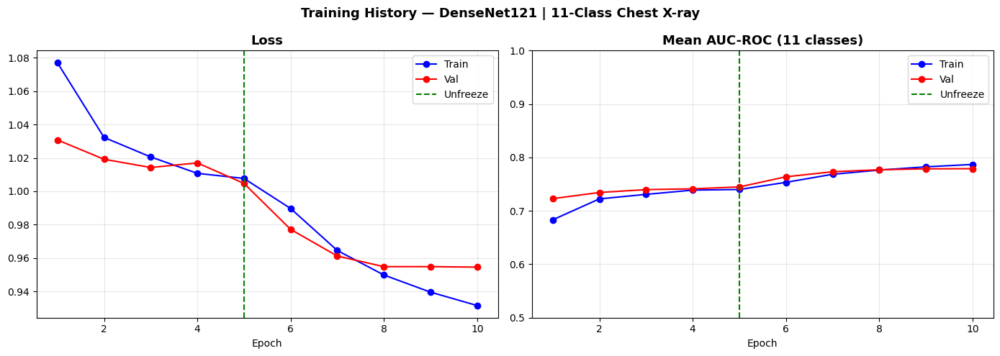

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ep = range(1, len(history['train_loss']) + 1)

axes[0].plot(ep, history['train_loss'], 'b-o', label='Train')
axes[0].plot(ep, history['val_loss'],   'r-o', label='Val')
axes[0].axvline(x=UNFREEZE_EPOCH, color='green', linestyle='--', label='Unfreeze')
axes[0].set_title('Loss', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(ep, history['train_auc'], 'b-o', label='Train')
axes[1].plot(ep, history['val_auc'],   'r-o', label='Val')
axes[1].axvline(x=UNFREEZE_EPOCH, color='green', linestyle='--', label='Unfreeze')
axes[1].set_title('Mean AUC-ROC (11 classes)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylim([0.5, 1.0])
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.suptitle('Training History — DenseNet121 | 11-Class Chest X-ray',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('/kaggle/working/training_curves.png', dpi=150, bbox_inches='tight')
plt.show()


In [44]:
checkpoint = torch.load(best_model_path, map_location=device, weights_only=False)
model.load_state_dict(checkpoint['model_state_dict'])
print(f"Loaded best model from epoch {checkpoint['epoch']}")

test_loss, test_auc, test_aucs = validate(model, test_loader, criterion)

print("\n" + "=" * 52)
print(f"  TEST SET RESULTS — 11 classes")
print("=" * 52)
print(f"  Test Loss    : {test_loss:.4f}")
print(f"  Mean AUC-ROC : {test_auc:.4f}")
print("=" * 52)
print(f"  {'Class':<22} {'AUC-ROC':>8}  {'Grade':>6}")
print(f"  {'-'*40}")
for cls, auc in zip(CFG.DISEASE_COLS, test_aucs):
    grade = "GOOD" if auc >= 0.80 else ("OK" if auc >= 0.70 else "LOW")
    tag   = " (healthy)" if cls == 'no_finding' else ""
    print(f"  {cls:<22} {auc:>8.4f}  {grade:>6}{tag}")
print("=" * 52)


Loaded best model from epoch 10


Validating:   0%|          | 0/98 [00:00<?, ?it/s]


  TEST SET RESULTS — 11 classes
  Test Loss    : 0.9678
  Mean AUC-ROC : 0.7718
  Class                   AUC-ROC   Grade
  ----------------------------------------
  no_finding               0.8795    GOOD (healthy)
  Atelectasis              0.7011      OK
  Cardiomegaly             0.8001    GOOD
  Effusion                 0.8388    GOOD
  Consolidation            0.7136      OK
  Edema                    0.8553    GOOD
  Pneumonia                0.6903     LOW
  Pneumothorax             0.7932      OK
  Infiltration             0.7463      OK
  Lung_Lesion              0.7147      OK
  Pleural_Thickening       0.7571      OK


In [45]:
import torch.serialization

final_path = '/kaggle/working/final_model.pt'

# Allow numpy globals so weights_only=True works on reload
torch.serialization.add_safe_globals(['numpy._core.multiarray.scalar'])

torch.save({
    'model_state_dict'       : model.state_dict(),
    'epoch'                  : checkpoint['epoch'],
    'best_val_auc'           : best_val_auc,
    'test_auc'               : test_auc,
    'per_class_test_auc'     : dict(zip(CFG.DISEASE_COLS, test_aucs)),
    'disease_cols'           : CFG.DISEASE_COLS,
    'num_classes'            : CFG.NUM_CLASSES,
    'img_size'               : CFG.IMG_SIZE,
    'architecture'           : 'DenseNet121',
    'mean'                   : CFG.MEAN,
    'std'                    : CFG.STD,
}, final_path)

size_mb = os.path.getsize(final_path) / (1024 * 1024)
print("=" * 45)
print(f"  final_model.pt saved!")
print(f"  Path      : {final_path}")
print(f"  Size      : {size_mb:.1f} MB")
print(f"  Classes   : {CFG.NUM_CLASSES} (10 diseases + No Finding)")
print(f"  Val AUC   : {best_val_auc:.4f}")
print(f"  Test AUC  : {test_auc:.4f}")
print("=" * 45)


  final_model.pt saved!
  Path      : /kaggle/working/final_model.pt
  Size      : 29.2 MB
  Classes   : 11 (10 diseases + No Finding)
  Val AUC   : 0.7789
  Test AUC  : 0.7718


In [46]:
from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    precision_score, recall_score, f1_score,
    confusion_matrix, classification_report,
    roc_curve, precision_recall_curve
)

# ── Get all predictions on test set ──────────────────────
model.eval()
all_labels, all_probs = [], []

with torch.no_grad():
    for imgs, labels in tqdm(test_loader, desc="Getting predictions"):
        imgs = imgs.to(device, non_blocking=True)
        with amp.autocast():
            outputs = model(imgs)
        all_labels.append(labels.cpu().numpy())
        all_probs.append(torch.sigmoid(outputs).cpu().numpy())

all_labels = np.concatenate(all_labels, axis=0)   # (N, 11)
all_probs  = np.concatenate(all_probs,  axis=0)   # (N, 11)
all_preds  = (all_probs >= 0.5).astype(int)        # threshold at 0.5

print(f"Test samples : {len(all_labels):,}")
print(f"Label shape  : {all_labels.shape}")
print(f"Pred shape   : {all_preds.shape}")


Getting predictions:   0%|          | 0/98 [00:00<?, ?it/s]

Test samples : 6,233
Label shape  : (6233, 11)
Pred shape   : (6233, 11)


In [47]:
print("\n" + "=" * 80)
print(f"  {'Class':<22} {'AUC-ROC':>8} {'AP':>8} {'Precision':>10} {'Recall':>8} {'F1':>8} {'Support':>9}")
print("=" * 80)

results = {}
for i, cls in enumerate(CFG.DISEASE_COLS):
    y_true = all_labels[:, i]
    y_prob = all_probs[:, i]
    y_pred = all_preds[:, i]

    try:    auc = roc_auc_score(y_true, y_prob)
    except: auc = 0.0
    try:    ap  = average_precision_score(y_true, y_prob)
    except: ap  = 0.0

    prec    = precision_score(y_true, y_pred, zero_division=0)
    rec     = recall_score(y_true, y_pred, zero_division=0)
    f1      = f1_score(y_true, y_pred, zero_division=0)
    support = int(y_true.sum())

    grade = "GOOD" if auc >= 0.80 else ("OK" if auc >= 0.70 else "LOW")
    tag   = " (healthy)" if cls == 'no_finding' else ""

    results[cls] = {
        'AUC': auc, 'AP': ap, 'Precision': prec,
        'Recall': rec, 'F1': f1, 'Support': support
    }

    print(f"  {cls:<22} {auc:>8.4f} {ap:>8.4f} {prec:>10.4f} {rec:>8.4f} {f1:>8.4f} {support:>9,}  [{grade}]{tag}")

# Summary row
mean_auc  = np.mean([v['AUC'] for v in results.values()])
mean_ap   = np.mean([v['AP']  for v in results.values()])
mean_prec = np.mean([v['Precision'] for v in results.values()])
mean_rec  = np.mean([v['Recall']    for v in results.values()])
mean_f1   = np.mean([v['F1']        for v in results.values()])

print("=" * 80)
print(f"  {'MEAN (macro)':<22} {mean_auc:>8.4f} {mean_ap:>8.4f} {mean_prec:>10.4f} {mean_rec:>8.4f} {mean_f1:>8.4f}")
print("=" * 80)



  Class                   AUC-ROC       AP  Precision   Recall       F1   Support
  no_finding               0.8795   0.7022     0.5221   0.8856   0.6569     1,643  [GOOD] (healthy)
  Atelectasis              0.7011   0.2587     0.2321   0.7214   0.3512       926  [OK]
  Cardiomegaly             0.8001   0.3509     0.2313   0.7259   0.3508       613  [GOOD]
  Effusion                 0.8388   0.6877     0.6002   0.7545   0.6686     2,000  [GOOD]
  Consolidation            0.7136   0.1286     0.1071   0.6987   0.1858       395  [OK]
  Edema                    0.8553   0.5121     0.4108   0.7699   0.5357     1,056  [GOOD]
  Pneumonia                0.6903   0.0489     0.0430   0.4812   0.0790       133  [LOW]
  Pneumothorax             0.7932   0.2870     0.2064   0.6441   0.3126       503  [OK]
  Infiltration             0.7463   0.6110     0.5928   0.6690   0.6286     2,474  [OK]
  Lung_Lesion              0.7147   0.1788     0.1136   0.5873   0.1904       395  [OK]
  Pleural_Thickeni

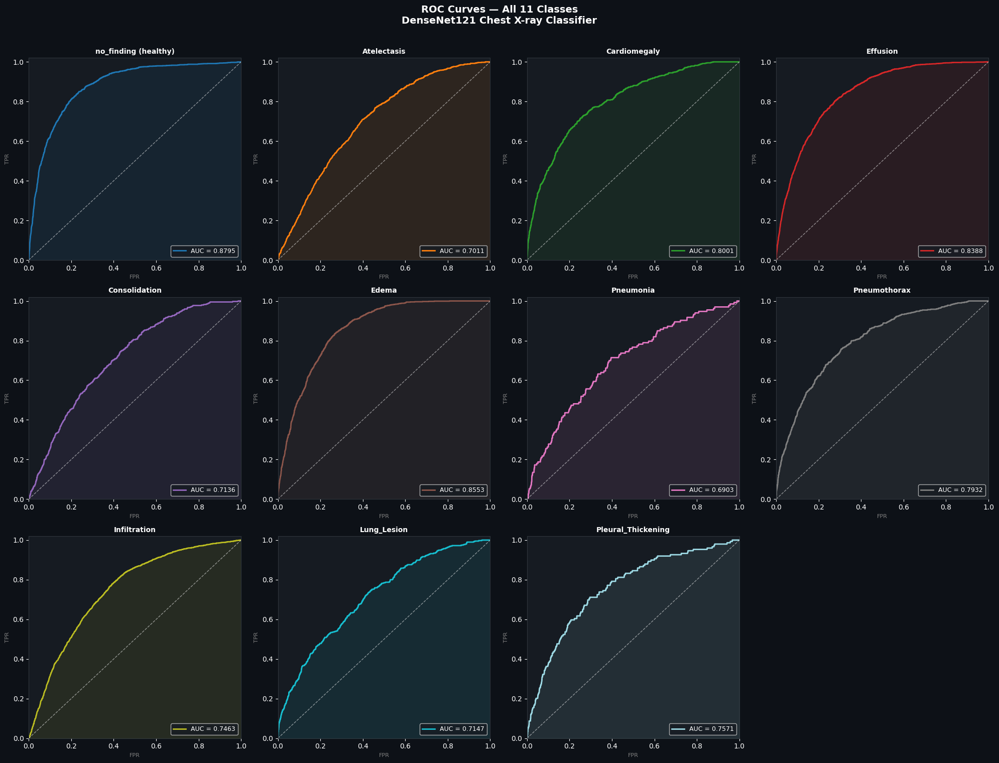

Saved: roc_curves.png


In [48]:
fig, axes = plt.subplots(3, 4, figsize=(20, 15))
axes = axes.flatten()
fig.patch.set_facecolor('#0d1117')

colors = plt.cm.tab20(np.linspace(0, 1, CFG.NUM_CLASSES))

for i, cls in enumerate(CFG.DISEASE_COLS):
    y_true = all_labels[:, i]
    y_prob = all_probs[:, i]

    try:
        fpr, tpr, _ = roc_curve(y_true, y_prob)
        auc         = roc_auc_score(y_true, y_prob)

        axes[i].plot(fpr, tpr, color=colors[i], lw=2,
                     label=f'AUC = {auc:.4f}')
        axes[i].plot([0, 1], [0, 1], 'w--', lw=1, alpha=0.5)
        axes[i].fill_between(fpr, tpr, alpha=0.1, color=colors[i])
        axes[i].set_xlim([0, 1])
        axes[i].set_ylim([0, 1.02])
        axes[i].set_facecolor('#161b22')
        axes[i].tick_params(colors='white')
        axes[i].spines[:].set_color('#30363d')
        tag = " (healthy)" if cls == 'no_finding' else ""
        axes[i].set_title(f'{cls}{tag}', fontsize=10,
                          color='white', fontweight='bold')
        axes[i].legend(fontsize=9, facecolor='#161b22',
                       labelcolor='white', loc='lower right')
        axes[i].set_xlabel('FPR', fontsize=8, color='gray')
        axes[i].set_ylabel('TPR', fontsize=8, color='gray')

    except Exception as e:
        axes[i].set_title(f'{cls}\nError', color='red')

# Hide unused subplot
axes[-1].set_visible(False)

fig.suptitle('ROC Curves — All 11 Classes\nDenseNet121 Chest X-ray Classifier',
             fontsize=14, fontweight='bold', color='white', y=1.01)
plt.tight_layout()
plt.savefig('/kaggle/working/roc_curves.png', dpi=150, bbox_inches='tight',
            facecolor='#0d1117')
plt.show()
print("Saved: roc_curves.png")


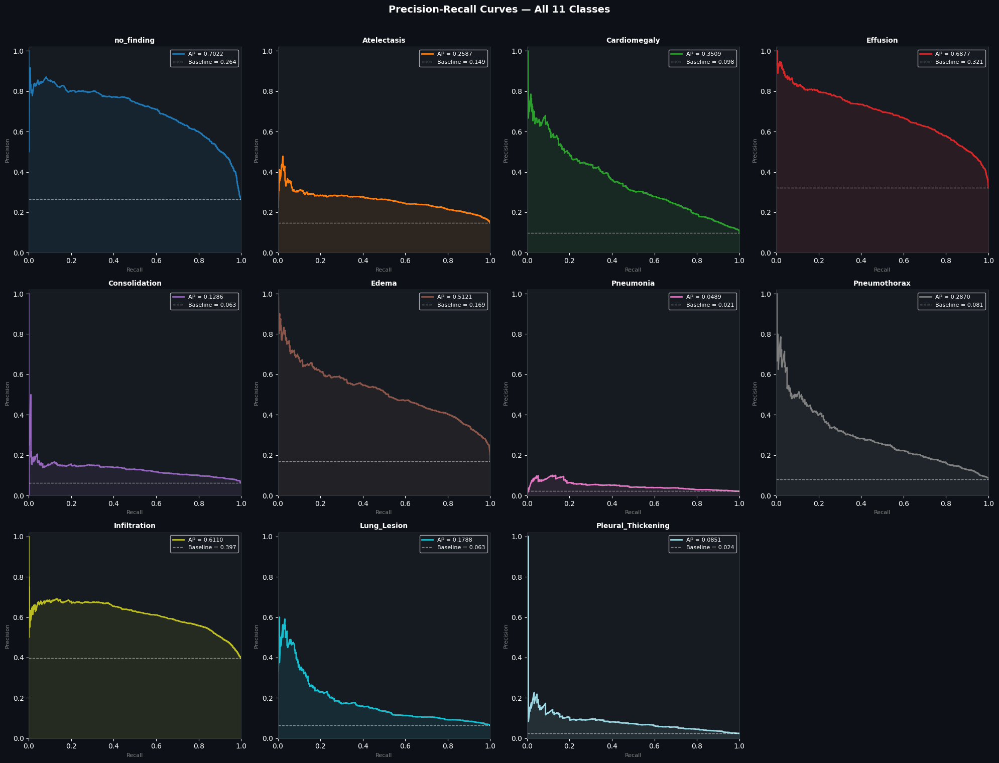

Saved: pr_curves.png


In [49]:
fig, axes = plt.subplots(3, 4, figsize=(20, 15))
axes = axes.flatten()
fig.patch.set_facecolor('#0d1117')

for i, cls in enumerate(CFG.DISEASE_COLS):
    y_true = all_labels[:, i]
    y_prob = all_probs[:, i]

    try:
        prec_c, rec_c, _ = precision_recall_curve(y_true, y_prob)
        ap                = average_precision_score(y_true, y_prob)
        baseline          = y_true.mean()

        axes[i].plot(rec_c, prec_c, color=colors[i], lw=2,
                     label=f'AP = {ap:.4f}')
        axes[i].axhline(y=baseline, color='white', linestyle='--',
                        lw=1, alpha=0.5, label=f'Baseline = {baseline:.3f}')
        axes[i].fill_between(rec_c, prec_c, alpha=0.1, color=colors[i])
        axes[i].set_xlim([0, 1])
        axes[i].set_ylim([0, 1.02])
        axes[i].set_facecolor('#161b22')
        axes[i].tick_params(colors='white')
        axes[i].spines[:].set_color('#30363d')
        axes[i].set_title(f'{cls}', fontsize=10,
                          color='white', fontweight='bold')
        axes[i].legend(fontsize=8, facecolor='#161b22',
                       labelcolor='white', loc='upper right')
        axes[i].set_xlabel('Recall',    fontsize=8, color='gray')
        axes[i].set_ylabel('Precision', fontsize=8, color='gray')

    except Exception as e:
        axes[i].set_title(f'{cls}\nError', color='red')

axes[-1].set_visible(False)

fig.suptitle('Precision-Recall Curves — All 11 Classes',
             fontsize=14, fontweight='bold', color='white', y=1.01)
plt.tight_layout()
plt.savefig('/kaggle/working/pr_curves.png', dpi=150, bbox_inches='tight',
            facecolor='#0d1117')
plt.show()
print("Saved: pr_curves.png")


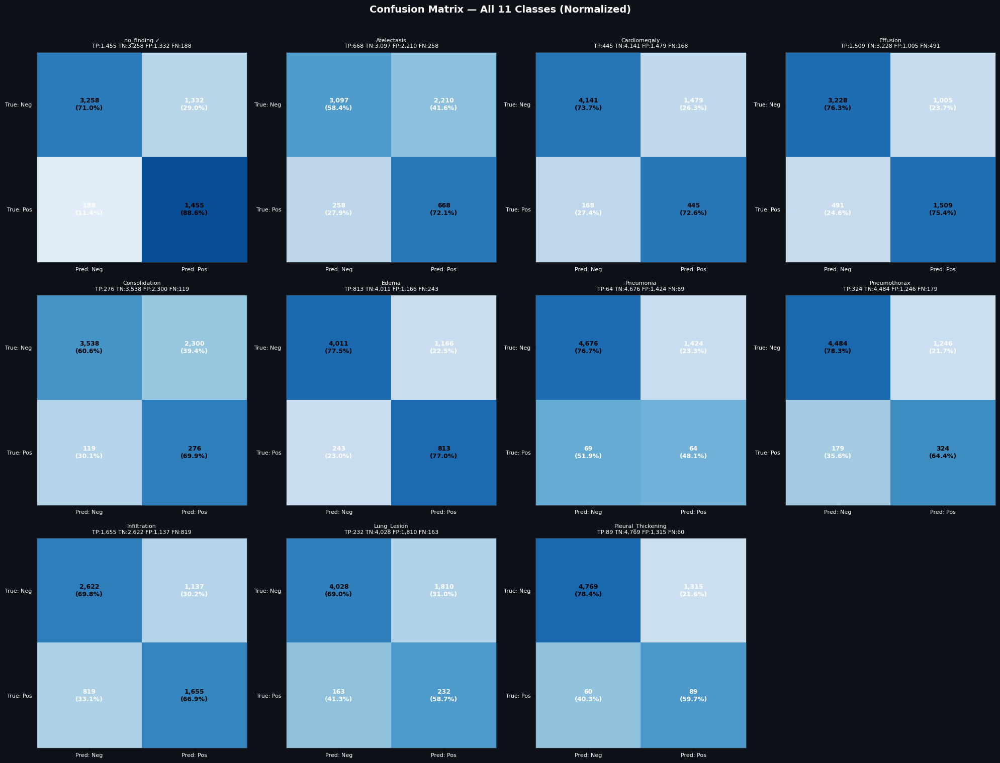

Saved: confusion_matrices.png


In [50]:
fig, axes = plt.subplots(3, 4, figsize=(20, 15))
axes = axes.flatten()
fig.patch.set_facecolor('#0d1117')

for i, cls in enumerate(CFG.DISEASE_COLS):
    y_true = all_labels[:, i]
    y_pred = all_preds[:, i]

    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()

    # Normalized confusion matrix
    cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

    im = axes[i].imshow(cm_norm, cmap='Blues', vmin=0, vmax=1)

    axes[i].set_xticks([0, 1])
    axes[i].set_yticks([0, 1])
    axes[i].set_xticklabels(['Pred: Neg', 'Pred: Pos'], color='white', fontsize=8)
    axes[i].set_yticklabels(['True: Neg', 'True: Pos'], color='white', fontsize=8)
    axes[i].set_facecolor('#161b22')
    axes[i].spines[:].set_color('#30363d')

    # Cell text
    for row in range(2):
        for col in range(2):
            raw = cm[row, col]
            pct = cm_norm[row, col]
            axes[i].text(col, row, f'{raw:,}\n({pct:.1%})',
                         ha='center', va='center',
                         color='white' if pct < 0.6 else 'black',
                         fontsize=9, fontweight='bold')

    tag = " ✓" if cls == 'no_finding' else ""
    axes[i].set_title(f'{cls}{tag}\nTP:{tp:,} TN:{tn:,} FP:{fp:,} FN:{fn:,}',
                      fontsize=8, color='white')

axes[-1].set_visible(False)

fig.suptitle('Confusion Matrix — All 11 Classes (Normalized)',
             fontsize=14, fontweight='bold', color='white', y=1.01)
plt.tight_layout()
plt.savefig('/kaggle/working/confusion_matrices.png', dpi=150,
            bbox_inches='tight', facecolor='#0d1117')
plt.show()
print("Saved: confusion_matrices.png")


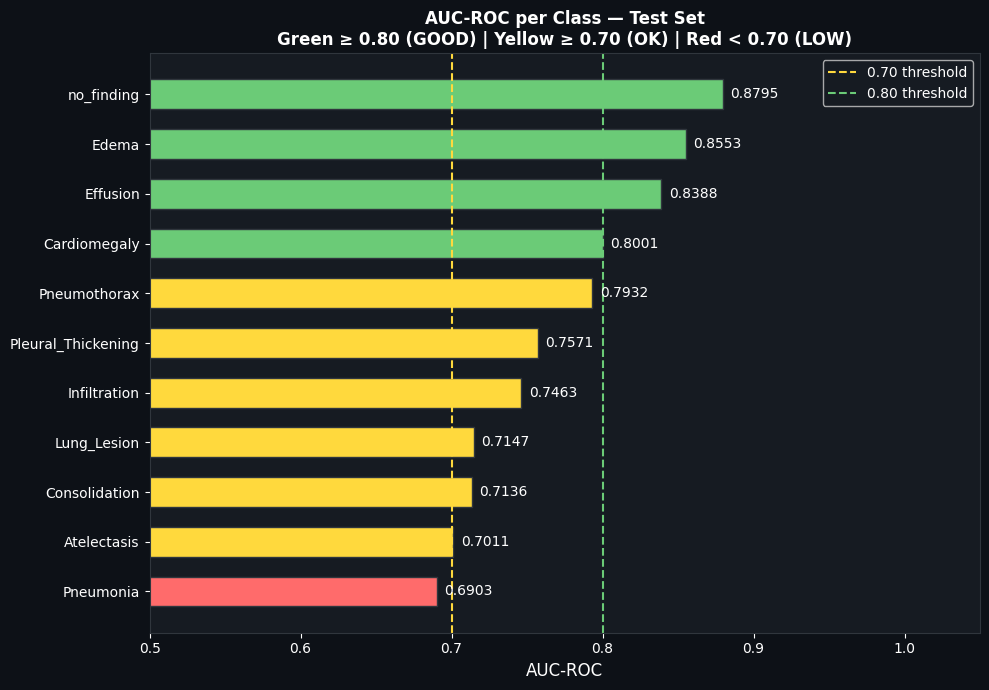


  Mean AUC-ROC  : 0.7718
  Mean F1 Score : 0.3704
  Mean Precision: 0.2839
  Mean Recall   : 0.6850

  GOOD (≥0.80)  : 4/11 classes
  OK   (≥0.70)  : 6/11 classes
  LOW  (<0.70)  : 1/11 classes


In [51]:
result_df = pd.DataFrame(results).T.sort_values('AUC', ascending=True)

fig, ax = plt.subplots(figsize=(10, 7))
fig.patch.set_facecolor('#0d1117')
ax.set_facecolor('#161b22')

colors_bar = ['#ff6b6b' if v < 0.70 else '#ffd93d' if v < 0.80
              else '#6bcb77' for v in result_df['AUC']]

bars = ax.barh(result_df.index, result_df['AUC'],
               color=colors_bar, edgecolor='#30363d', height=0.6)

for bar, val in zip(bars, result_df['AUC']):
    ax.text(val + 0.005, bar.get_y() + bar.get_height()/2,
            f'{val:.4f}', va='center', color='white', fontsize=10)

ax.axvline(x=0.70, color='#ffd93d', linestyle='--', lw=1.5, label='0.70 threshold')
ax.axvline(x=0.80, color='#6bcb77', linestyle='--', lw=1.5, label='0.80 threshold')
ax.set_xlim([0.5, 1.05])
ax.set_xlabel('AUC-ROC', fontsize=12, color='white')
ax.set_title('AUC-ROC per Class — Test Set\n'
             'Green ≥ 0.80 (GOOD) | Yellow ≥ 0.70 (OK) | Red < 0.70 (LOW)',
             fontsize=12, fontweight='bold', color='white')
ax.tick_params(colors='white')
ax.spines[:].set_color('#30363d')
ax.legend(facecolor='#161b22', labelcolor='white', fontsize=10)

plt.tight_layout()
plt.savefig('/kaggle/working/auc_summary.png', dpi=150,
            bbox_inches='tight', facecolor='#0d1117')
plt.show()

# Final print
print("\n" + "=" * 45)
print(f"  Mean AUC-ROC  : {mean_auc:.4f}")
print(f"  Mean F1 Score : {mean_f1:.4f}")
print(f"  Mean Precision: {mean_prec:.4f}")
print(f"  Mean Recall   : {mean_rec:.4f}")
good  = sum(1 for v in results.values() if v['AUC'] >= 0.80)
ok    = sum(1 for v in results.values() if 0.70 <= v['AUC'] < 0.80)
low   = sum(1 for v in results.values() if v['AUC'] < 0.70)
print(f"\n  GOOD (≥0.80)  : {good}/11 classes")
print(f"  OK   (≥0.70)  : {ok}/11 classes")
print(f"  LOW  (<0.70)  : {low}/11 classes")
print("=" * 45)
